# Lab 6 of 8: Reinforcement learning


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

## Part A: Tabular Q-learning in a 4 x 4 GridWorld

In [2]:
rng = np.random.default_rng(42)

ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

In [3]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))
    return int(np.argmax(Q[state]))

training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

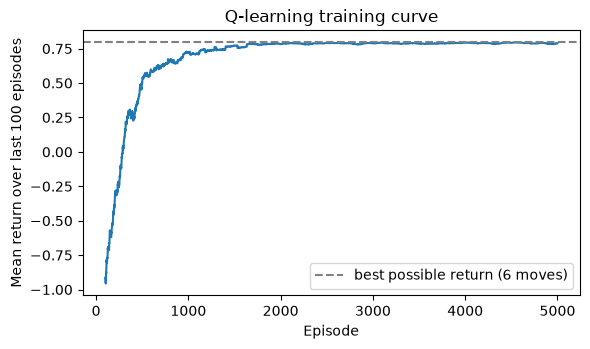

In [4]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


## Part B

In [6]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)
Q_loaded = np.load(q_path)

policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        if (r, c) == GOAL:
            policy[r, c] = "GOAL"
        elif (r, c) == TRAP:
            policy[r, c] = "TRAP"
        else:
            policy[r, c] = ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


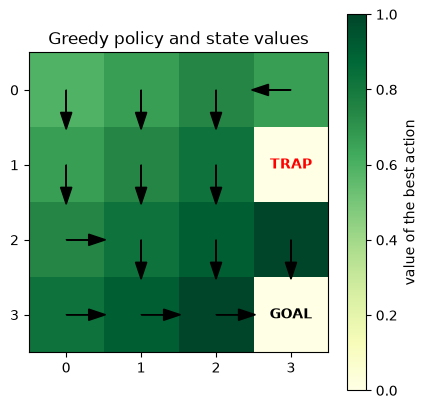

In [7]:
def plot_policy(Q_table, title, goal=GOAL, trap=TRAP):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == goal:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == trap:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_policy(Q_loaded, "Greedy policy and state values")

## Takeaway
After 5,000 episodes of training, the greedy policy reached the goal in all 200 evaluation episodes (success rate 1.0) with a mean return of 0.8, which is the best possible return for the six-move route. The first action learned at the start was "down". The training curve rises as exploration decays. The saved Q-table reloads and gives a policy that routes down the left side and across the bottom, around the trap at (1, 3).

## Try it yourself

**Predictions (made before running):**
- **Step cost -0.5:** the agent should still head for the goal, but each move costs more, so the return should be lower.
- **Step cost -1.5:** moves are so costly that the agent might prefer to end the game quickly by entering the trap.
- **Trap moved to (2, 2):** the agent should change its route to avoid the new trap square but still reach the goal.
- **Discount 0.5:** the agent values future rewards less, so I expected it might struggle, but the path to the goal is short.

**Results:**

| Change | Success rate | Mean return |
|---|---|---|
| Step cost -0.5 | 1.00 | -1.50 |
| Step cost -1.5 | 0.00 | -5.50 |
| Trap moved to (2, 2) | 1.00 | 0.80 |
| Discount 0.5 | 1.00 | 0.80 |

With a step cost of -0.5 the agent still reached the goal every time, but the return dropped from 0.8 to -1.5 because each of the six moves is more expensive. With -1.5 the agent went for the trap instead. Reaching the trap costs 3 moves plus the trap penalty (-5.5), while the goal needs 5 moves plus the goal reward (-6.5), so ending the game early is the better choice. Moving the trap only changed the route. The discount of 0.5 was enough for the short path in this small grid.

In [8]:
def make_step(step_cost=-0.04, trap=TRAP):
    def step_fn(state, action):
        r, c = state
        dr, dc = ACTIONS[action]
        nxt = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
        if nxt == GOAL:
            return nxt, 1.0, True
        if nxt == trap:
            return nxt, -1.0, True
        return nxt, step_cost, False
    return step_fn

def train_q(step_fn, gamma=0.95, decay=0.9985, episodes=5000, alpha=0.15, seed=42):
    local_rng = np.random.default_rng(seed)
    Q_new = np.zeros((ROWS, COLS, len(ACTIONS)))
    eps = 1.0
    for _ in range(episodes):
        state = START
        for _ in range(100):
            if local_rng.random() < eps:
                action = int(local_rng.integers(len(ACTIONS)))
            else:
                action = int(np.argmax(Q_new[state]))
            nxt, reward, done = step_fn(state, action)
            target = reward if done else reward + gamma * np.max(Q_new[nxt])
            Q_new[state][action] += alpha * (target - Q_new[state][action])
            state = nxt
            if done:
                break
        eps = max(0.05, eps * decay)
    return Q_new

def evaluate_greedy(Q_table, step_fn, episodes=200):
    wins, totals = 0, []
    for _ in range(episodes):
        state, total = START, 0.0
        for _ in range(100):
            state, reward, done = step_fn(state, int(np.argmax(Q_table[state])))
            total += reward
            if done:
                wins += int(state == GOAL)
                break
        totals.append(total)
    return wins / episodes, float(np.mean(totals))

step cost -0.5         success rate = 1.00  mean return = -1.50


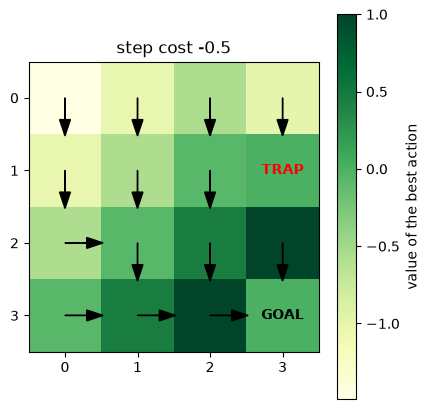

step cost -1.5         success rate = 0.00  mean return = -5.50


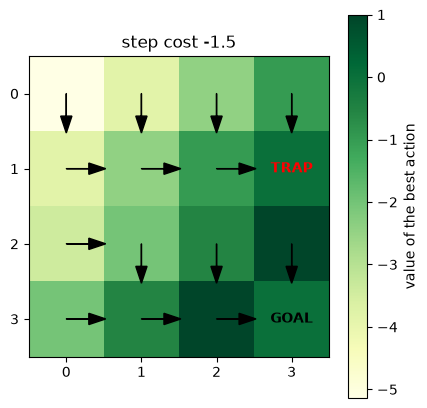

trap moved to (2, 2)   success rate = 1.00  mean return = 0.80


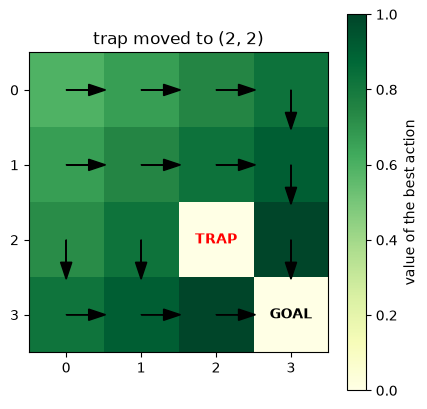

discount 0.5           success rate = 1.00  mean return = 0.80


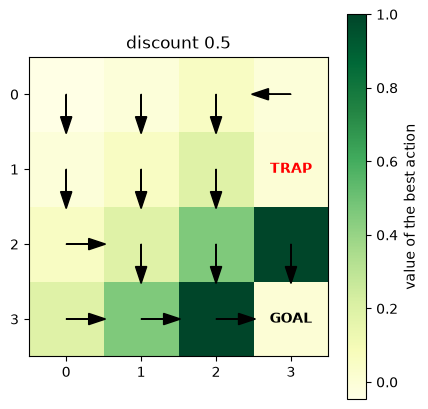

In [9]:
experiments = {
    "step cost -0.5": dict(step_cost=-0.5),
    "step cost -1.5": dict(step_cost=-1.5),
    "trap moved to (2, 2)": dict(trap=(2, 2)),
    "discount 0.5": dict(gamma=0.5),
}

for label, settings in experiments.items():
    step_kwargs = {k: v for k, v in settings.items() if k in ("step_cost", "trap")}
    train_kwargs = {k: v for k, v in settings.items() if k in ("gamma", "decay")}
    step_fn = make_step(**step_kwargs)
    Q_exp = train_q(step_fn, **train_kwargs)
    success, mean_return = evaluate_greedy(Q_exp, step_fn)
    print(f"{label:22s} success rate = {success:.2f}  mean return = {mean_return:.2f}")
    plot_policy(Q_exp, label, trap=settings.get("trap", TRAP))

## Self understanding

**1. What are the state, action, reward, and transition in a reinforcement-learning formulation?**
In this GridWorld the state is the agent's position in the grid, a (row, column) pair. The action is one of four moves: up, down, left or right. The reward is the number the environment returns after each move: -0.04 for an ordinary move, +1 for reaching the goal and -1 for entering the trap. The transition is the rule that gives the next state from the current state and action. Here it is deterministic, and a move into a wall leaves the position unchanged.

**2. What two pieces of information appear in the tabular Q-learning backup value?**
The backup target combines the immediate reward just received, and the discounted value of the best action in the next state, gamma times the maximum Q-value there. In other words it is the reward now plus the estimated future value. The Q-value is moved a step of size alpha toward this target. At a terminal state the target is just the reward.

**3. Why should the exploratory training policy be evaluated separately from the final greedy policy?**
During training the agent sometimes takes random actions (epsilon-greedy), so its returns are lower and noisier than what the learned policy can achieve, and they mix learning progress with exploration. The final policy is deployed by always choosing the highest-valued action. Evaluating it separately with exploration switched off measures the performance that would actually be seen and gives a clean success rate and mean return.